# Disease Prediction from Symptoms — Jupyter Notebook

This notebook preserves the project's existing preprocessing, six-model comparison, evaluation, and saved-model structure. It uses the dataset path provided by you. Run cells from top to bottom. The GUI remains a separate `symptom_checker_gui.py` application.

**Dataset:** `C:\Users\pd781\Downloads\Final_Augmented_dataset_Diseases_and_Symptoms.csv`  
**Outputs/model:** `C:\Users\pd781\Downloads\disease_prediction_output`

> Educational demonstration only; predictions are not a medical diagnosis.

## 1. Imports and settings


In [ ]:
import os, json, difflib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
 
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
 
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
 
DATA_PATH = r"C:\Users\pd781\Downloads\Final_Augmented_dataset_Diseases_and_Symptoms.csv"            # dataset folder (or the .csv / .zip file itself)
OUT_DIR   = r"D:\AML\aml project\disease_prediction_output"   # plots + saved model go here
 
# If DATA_PATH is a folder, find the CSV (or zip) inside it automatically
if os.path.isdir(DATA_PATH):
    found = [f for f in os.listdir(DATA_PATH) if f.lower().endswith((".csv", ".zip"))]
    if not found:
        raise FileNotFoundError(f"No .csv or .zip file found inside {DATA_PATH}")
    DATA_PATH = os.path.join(DATA_PATH, found[0])
print("Using dataset file:", DATA_PATH)
MIN_ROWS = 20    # keep only diseases having at least this many UNIQUE rows
MAX_ROWS = 100   # use at most this many rows per disease (keeps training fast, classes balanced)
os.makedirs(OUT_DIR, exist_ok=True)
 


Using dataset file: C:\Users\pd781\Downloads\Final_Augmented_dataset_Diseases_and_Symptoms.csv


## 2. Load dataset


In [ ]:
# int8 columns -> uses ~8x less RAM than default int64
cols = pd.read_csv(DATA_PATH, nrows=0).columns
dtypes = {c: np.int8 for c in cols[1:]}
df = pd.read_csv(DATA_PATH, dtype=dtypes)
TARGET = df.columns[0]                      # 'diseases'
print("Raw shape:", df.shape)
df.head()
 


Raw shape: (246945, 378)


,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,...,stuttering or stammering,problems with orgasm,nose deformity,lump over jaw,sore in nose,hip weakness,back swelling,ankle stiffness or tightness,ankle weakness,neck weakness
0,panic disorder,1,0,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,panic disorder,0,0,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,panic disorder,1,1,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,panic disorder,1,0,0,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,panic disorder,1,1,0,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0


## 3. EDA (Exploratory Data Analysis)


Missing values : 0
Duplicate rows : 57298
Diseases       : 773
Symptoms/row   : mean = 5.33, max = 12


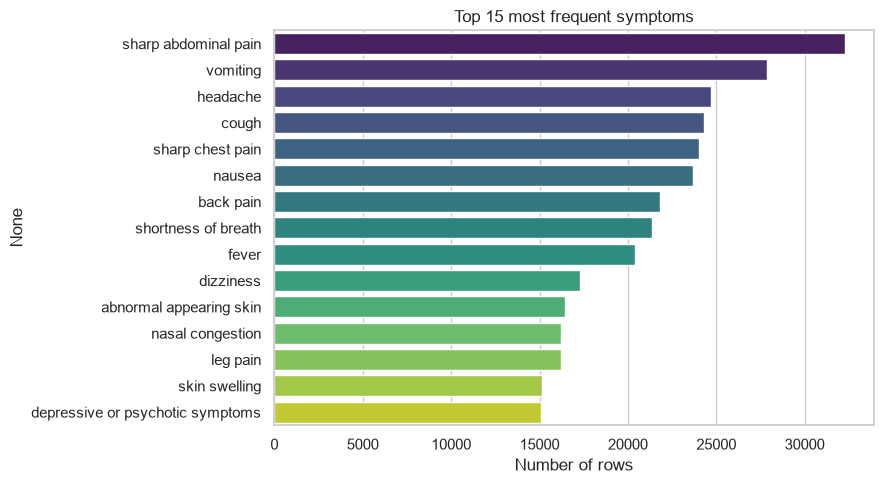

In [ ]:
print("Missing values :", int(df.isnull().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))
print("Diseases       :", df[TARGET].nunique())
sym_per_row = df.iloc[:, 1:].to_numpy().sum(axis=1)
print("Symptoms/row   : mean = %.2f, max = %d" % (sym_per_row.mean(), sym_per_row.max()))
 
top_sym = df.drop(columns=TARGET).sum().sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_sym.values, y=top_sym.index, palette="viridis")
plt.title("Top 15 most frequent symptoms"); plt.xlabel("Number of rows")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "top_symptoms.png"), dpi=150); plt.show()
 


## 4. Preprocessing


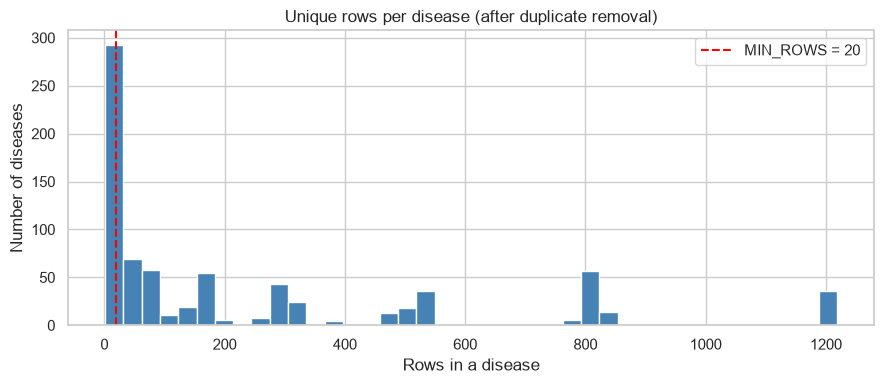

Rows: raw 246945 -> unique 189647 -> used 43294
Diseases used: 512   Symptoms: 377
Train: (34635, 377) Test: (8659, 377)


In [ ]:
raw_rows = len(df)
# (a) remove duplicates -> otherwise same row can be in train AND test (data leakage)
df = df.drop_duplicates().reset_index(drop=True)
after_dedupe = len(df)
unique_per_disease = df[TARGET].value_counts()
 
# plot class imbalance AFTER duplicate removal
plt.figure(figsize=(9, 4))
plt.hist(
    unique_per_disease.to_numpy(dtype=np.int64),
    bins=40,
    color="steelblue"
)
plt.axvline(MIN_ROWS, color="red", ls="--", label=f"MIN_ROWS = {MIN_ROWS}")
plt.title("Unique rows per disease (after duplicate removal)")
plt.xlabel("Rows in a disease"); plt.ylabel("Number of diseases"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "class_distribution.png"), dpi=150); plt.show()
 
# (b) drop very rare diseases (too few rows to learn or test on)
df = df[df[TARGET].map(unique_per_disease) >= MIN_ROWS]
# (c) cap rows per disease -> balanced classes + faster training
df = (df.sample(frac=1, random_state=RANDOM_STATE)
        .groupby(TARGET, group_keys=False).head(MAX_ROWS).reset_index(drop=True))
 
X = df.drop(columns=TARGET)
symptom_cols = list(X.columns)
le = LabelEncoder()
y = le.fit_transform(df[TARGET])
print(f"Rows: raw {raw_rows} -> unique {after_dedupe} -> used {len(df)}")
print(f"Diseases used: {len(le.classes_)}   Symptoms: {len(symptom_cols)}")
 
X_train, X_test, y_train, y_test = train_test_split(
    X.values.astype(np.float32), y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
 


## 5. Train & compare 6 models


done: Logistic Regression
done: KNN
done: Decision Tree
done: Naive Bayes
done: Random Forest
done: SVM (Linear)
              Model  CV Accuracy  Test Accuracy  Top-3 Accuracy  Test F1 (weighted)
Logistic Regression       0.8554         0.8627          0.9598              0.8622
       SVM (Linear)       0.8462         0.8552          0.9540              0.8545
      Random Forest       0.8142         0.8239          0.9417              0.8241
        Naive Bayes       0.8058         0.8206          0.9219              0.8046
                KNN       0.7377         0.7564          0.8645              0.7572
      Decision Tree       0.6798         0.7092          0.7223              0.7107


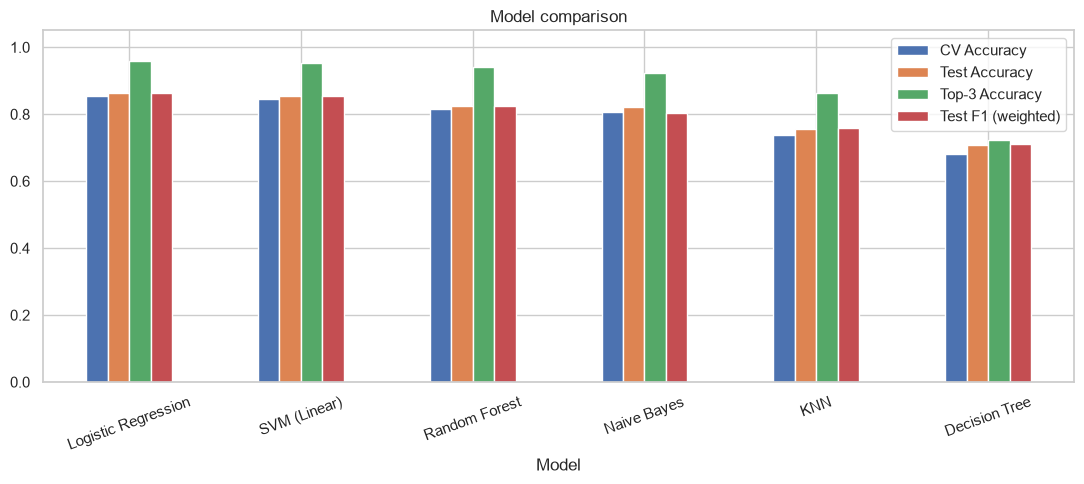

In [ ]:
def topk_accuracy(model, Xt, yt, k=3):
    """Is the TRUE disease among the model's k most likely diseases?"""
    scores = model.predict_proba(Xt) if hasattr(model, "predict_proba") else model.decision_function(Xt)
    top = np.argsort(-scores, axis=1)[:, :k]
    classes = model.classes_
    return float(np.mean([yt[i] in classes[top[i]] for i in range(len(yt))]))
 
models = {
    "Logistic Regression": LogisticRegression(max_iter=100),
    "KNN":                 KNeighborsClassifier(n_neighbors=5),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes":         BernoulliNB(),
    # max_leaf_nodes keeps RAM small (773-class trees can otherwise take GBs)
    "Random Forest":       RandomForestClassifier(n_estimators=30, max_leaf_nodes=3000,
                                                  random_state=RANDOM_STATE, n_jobs=1),
    "SVM (Linear)":        LinearSVC(C=0.5, max_iter=300),
}
 
rows, fitted = [], {}
for name, model in models.items():
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"Model": name,
                 "CV Accuracy": cv_acc,
                 "Test Accuracy": accuracy_score(y_test, pred),
                 "Top-3 Accuracy": topk_accuracy(model, X_test, y_test, 3),
                 "Test F1 (weighted)": f1_score(y_test, pred, average="weighted")})
    fitted[name] = model
    print(f"done: {name}")
 
results = pd.DataFrame(rows).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
print(results.round(4).to_string(index=False))
results.to_csv(os.path.join(OUT_DIR, "results.csv"), index=False)
 
results.set_index("Model")[["CV Accuracy", "Test Accuracy", "Top-3 Accuracy", "Test F1 (weighted)"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1.05))
plt.title("Model comparison"); plt.xticks(rotation=20); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "model_comparison.png"), dpi=150); plt.show()
 


## 6. Hyperparameter tuning (GridSearchCV) on the best linear model: Logistic Regression


In [ ]:
grid = GridSearchCV(LogisticRegression(max_iter=100), {"C": [0.1, 1, 10]},
                    cv=cv, scoring="accuracy", n_jobs=1)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print("Best params:", grid.best_params_, "| best CV accuracy:", round(grid.best_score_, 4))
 


Best params: {'C': 1} | best CV accuracy: 0.8554


## 7. Final evaluation of the tuned model


{
  "best_params": {
    "C": 1
  },
  "cv_accuracy": 0.8554352533564313,
  "test_accuracy": 0.862686222427532,
  "top3_accuracy": 0.959810601686107,
  "top5_accuracy": 0.9804827347268738,
  "f1_weighted": 0.8621744371263922,
  "precision_weighted": 0.8742205146296395,
  "recall_weighted": 0.862686222427532,
  "raw_rows": 246945,
  "unique_rows": 189647,
  "used_rows": 43294,
  "n_diseases": 512,
  "n_symptoms": 377,
  "train_rows": 34635,
  "test_rows": 8659
}


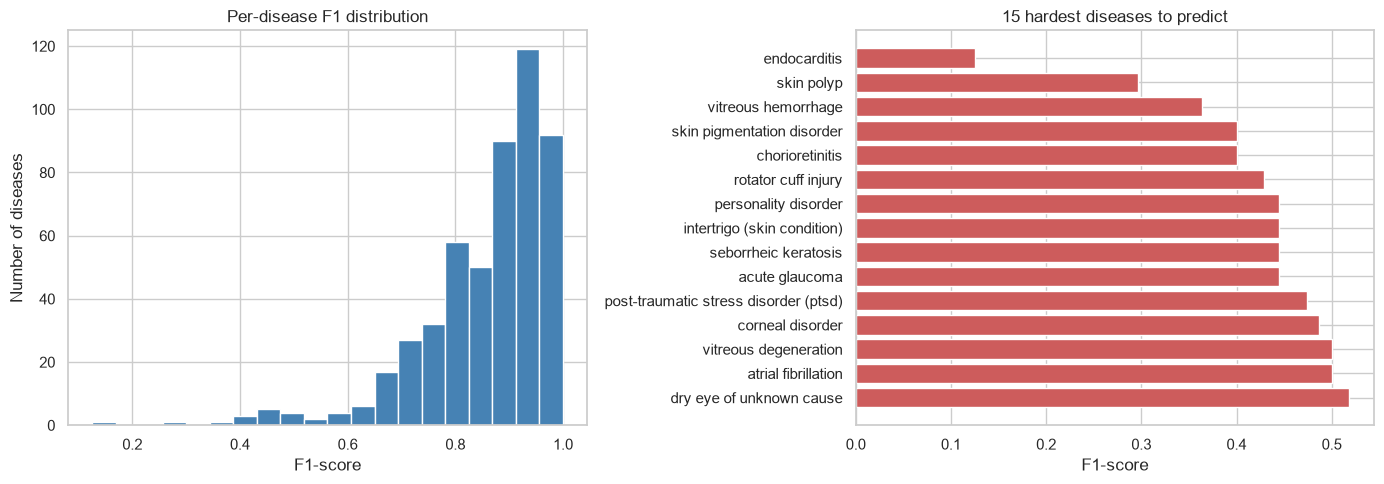

In [ ]:
y_pred = best_model.predict(X_test)
final = {
    "best_params": grid.best_params_,
    "cv_accuracy": float(grid.best_score_),
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "top3_accuracy": topk_accuracy(best_model, X_test, y_test, 3),
    "top5_accuracy": topk_accuracy(best_model, X_test, y_test, 5),
    "f1_weighted": float(f1_score(y_test, y_pred, average="weighted")),
    "precision_weighted": float(precision_recall_fscore_support(y_test, y_pred, average="weighted")[0]),
    "recall_weighted": float(precision_recall_fscore_support(y_test, y_pred, average="weighted")[1]),
    "raw_rows": int(raw_rows), "unique_rows": int(after_dedupe), "used_rows": int(len(df)),
    "n_diseases": int(len(le.classes_)), "n_symptoms": int(len(symptom_cols)),
    "train_rows": int(len(y_train)), "test_rows": int(len(y_test)),
}
print(json.dumps(final, indent=2))
 
# 773-class confusion matrix is unreadable, so we look at per-disease F1 instead
p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=range(len(le.classes_)), zero_division=0)
per_class = pd.DataFrame({"disease": le.classes_, "f1": f}).sort_values("f1")
final["share_f1_ge_0.9"] = float((per_class.f1 >= 0.9).mean())
final["share_f1_lt_0.5"] = float((per_class.f1 < 0.5).mean())
final["worst10"] = per_class.head(10).values.tolist()
final["best5"] = per_class.tail(5).values.tolist()
 
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(per_class.f1, bins=20, color="steelblue")
ax[0].set_title("Per-disease F1 distribution"); ax[0].set_xlabel("F1-score"); ax[0].set_ylabel("Number of diseases")
worst = per_class.head(15)
ax[1].barh(worst.disease, worst.f1, color="indianred"); ax[1].invert_yaxis()
ax[1].set_title("15 hardest diseases to predict"); ax[1].set_xlabel("F1-score")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "per_disease_f1.png"), dpi=150); plt.show()
 


## 8. Feature importance (Random Forest) - which symptoms matter most?


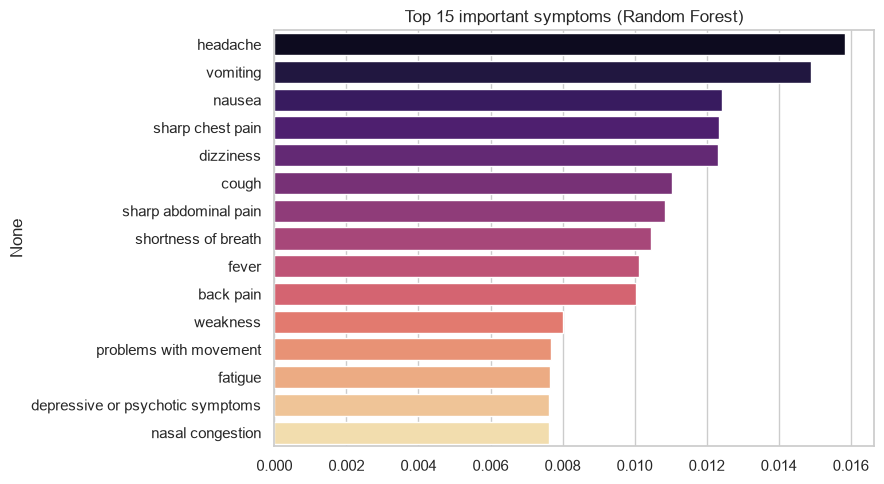

In [ ]:
imp = pd.Series(fitted["Random Forest"].feature_importances_, index=symptom_cols).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 5))
sns.barplot(x=imp.values, y=imp.index, palette="magma")
plt.title("Top 15 important symptoms (Random Forest)"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "feature_importance.png"), dpi=150); plt.show()
final["top_features"] = list(imp.index[:5])
 


## 9. Save model


In [ ]:
joblib.dump({"model": best_model, "label_encoder": le, "symptoms": symptom_cols},
            os.path.join(OUT_DIR, "disease_model.joblib"))
print("Saved:", os.path.join(OUT_DIR, "disease_model.joblib"))
 


Saved: D:\AML\aml project\disease_prediction_output\disease_model.joblib


## 10. Predict from user symptoms


In [ ]:
def predict_disease(symptoms, top_k=3):
    """symptoms: list of symptom names exactly like the dataset, e.g. ['fever', 'cough', 'sore throat']"""
    bundle = joblib.load(os.path.join(OUT_DIR, "disease_model.joblib"))
    model, enc, cols = bundle["model"], bundle["label_encoder"], bundle["symptoms"]
    symptoms = [s.strip().lower() for s in symptoms]
    for s in [s for s in symptoms if s not in cols]:
        print(f"Unknown symptom '{s}'. Did you mean: {difflib.get_close_matches(s, cols, n=3)}")
    x = pd.DataFrame([[1.0 if c in symptoms else 0.0 for c in cols]], columns=cols)
    proba = model.predict_proba(x.values)[0]
    top = np.argsort(proba)[::-1][:top_k]
    print("\nSymptoms:", symptoms)
    for i in top:
        print(f"  {enc.classes_[i]:<40} {proba[i]*100:5.1f}%")
    print("  (Educational project only - not a medical diagnosis. Consult a doctor.)")
    return [(enc.classes_[i], float(proba[i])) for i in top]
 
demo = {
    "demo1": predict_disease(["fever", "cough", "sore throat", "nasal congestion"]),
    "demo2": predict_disease(["sharp chest pain", "shortness of breath"]),
}
final["demo"] = demo
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as fh:
    json.dump(final, fh, indent=2)
 



Symptoms: ['fever', 'cough', 'sore throat', 'nasal congestion']
  conjunctivitis due to bacteria            17.3%
  tracheitis                                10.3%
  interstitial lung disease                  7.7%
  (Educational project only - not a medical diagnosis. Consult a doctor.)

Symptoms: ['sharp chest pain', 'shortness of breath']
  sarcoidosis                                3.5%
  malignant hypertension                     3.0%
  fluid overload                             2.9%
  (Educational project only - not a medical diagnosis. Consult a doctor.)


## 10. Extra Analysis: accuracy vs. number of symptoms
This simulation uses the existing held-out test set and the trained best model. It shows how top-1/top-3 accuracy changes when only a subset of symptoms is supplied.

,Symptoms entered,Top-1 accuracy,Top-3 accuracy,Test rows
0,1,0.0519,0.1420,2888
1,2,0.3006,0.5589,2888
2,3,0.5686,0.8248,2888
3,4,0.7493,0.9297,2888
4,5,0.8608,0.9754,2888
5,6,0.9290,0.9917,2888


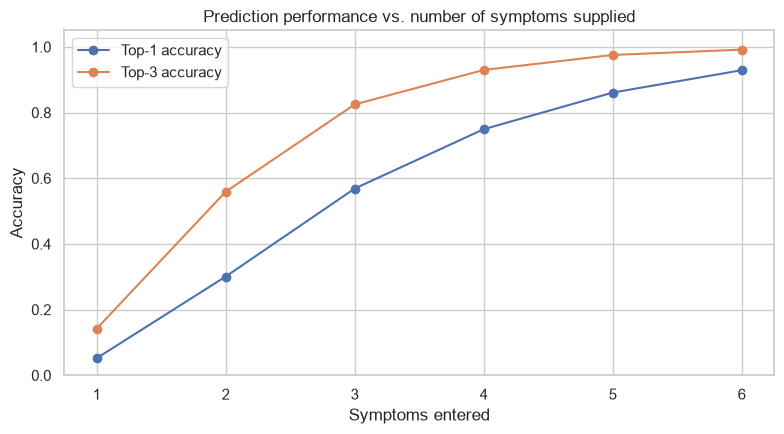

In [ ]:
# Extra analysis 1: simulate fewer entered symptoms using the existing test set.
rng = np.random.default_rng(RANDOM_STATE)
rows_with_enough = np.where(X_test.sum(axis=1) >= 6)[0]
Xr, yr = X_test[rows_with_enough], y_test[rows_with_enough]

if len(yr) == 0:
    print("No test rows have six or more symptoms; skipping symptom-count simulation.")
else:
    sim_rows = []
    for k in range(1, 7):
        Xs = np.zeros_like(Xr)
        for i in range(len(Xr)):
            on = np.flatnonzero(Xr[i])
            if len(on) >= k:
                Xs[i, rng.choice(on, size=k, replace=False)] = 1
            else:
                Xs[i, on] = 1
        sim_rows.append({"Symptoms entered": k,
                         "Top-1 accuracy": float(np.mean(best_model.predict(Xs) == yr)),
                         "Top-3 accuracy": topk_accuracy(best_model, Xs, yr, 3),
                         "Test rows": len(yr)})
    symptom_simulation = pd.DataFrame(sim_rows)
    display(symptom_simulation.round(4))
    ax = symptom_simulation.plot(x="Symptoms entered", y=["Top-1 accuracy", "Top-3 accuracy"], marker="o", figsize=(8, 4.5), ylim=(0, 1.05))
    ax.set_title("Prediction performance vs. number of symptoms supplied")
    ax.set_ylabel("Accuracy")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "accuracy_vs_symptoms.png"), dpi=150)
    plt.show()


## 11. Extra Analysis: most frequently confused disease pairs

In [ ]:
# Compare true and predicted labels for the held-out test set.
y_pred_extra = best_model.predict(X_test)
wrong_predictions = pd.DataFrame({"Actual disease": le.classes_[y_test], "Predicted disease": le.classes_[y_pred_extra]})
wrong_predictions = wrong_predictions[wrong_predictions["Actual disease"] != wrong_predictions["Predicted disease"]]
confused_pairs = wrong_predictions.value_counts().head(10).reset_index(name="Count")
if confused_pairs.empty:
    print("No incorrect predictions in this test set.")
else:
    display(confused_pairs)
    confused_pairs.to_csv(os.path.join(OUT_DIR, "confused_pairs.csv"), index=False)
    print("Saved confused_pairs.csv to", OUT_DIR)


,Actual disease,Predicted disease,Count
0,acute glaucoma,vitreous degeneration,7
1,noninfectious gastroenteritis,infectious gastroenteritis,7
2,gum disease,tooth disorder,7
3,intestinal obstruction,ischemia of the bowel,6
4,uterine fibroids,idiopathic irregular menstrual cycle,6
5,cholecystitis,gallstone,5
6,cataract,retinal detachment,5
7,schizophrenia,psychotic disorder,5
8,dry eye of unknown cause,corneal disorder,5
9,pneumonia,acute bronchospasm,5


Saved confused_pairs.csv to D:\AML\aml project\disease_prediction_output


## 12. Try a symptom-based prediction
Select symptom names in the cell below. This is a dataset-model prediction for educational use only, not a diagnosis.

In [ ]:
# Edit this list with exact symptom column names from the dataset.
selected_symptoms = []  # Example: [symptom_cols[0], symptom_cols[1]]

if not selected_symptoms:
    print("Add one or more exact symptom names to selected_symptoms, then rerun this cell.")
else:
    unknown = [s for s in selected_symptoms if s not in symptom_cols]
    if unknown:
        print("Unknown symptom column(s):", unknown)
        print("Tip: inspect symptom_cols or use the search below.")
    else:
        sample = np.zeros((1, len(symptom_cols)), dtype=np.float32)
        for symptom in selected_symptoms:
            sample[0, symptom_cols.index(symptom)] = 1
        predicted_code = int(best_model.predict(sample)[0])
        print("Predicted disease label:", le.inverse_transform([predicted_code])[0])
        if hasattr(best_model, "predict_proba"):
            probs = best_model.predict_proba(sample)[0]
            top_idx = np.argsort(probs)[::-1][:5]
            display(pd.DataFrame({"Disease": le.inverse_transform(best_model.classes_[top_idx]), "Model score": probs[top_idx]}))
        else:
            print("This model does not provide calibrated probability scores.")
        print("Reminder: this is not medical advice or a diagnosis.")


Add one or more exact symptom names to selected_symptoms, then rerun this cell.
